In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

rawEURUSD = pd.read_csv("EURUSD.csv", sep=",", index_col= "Date", header=0, parse_dates=True)

In [2]:
rawEURUSD.head()

,EURUSD
Date,
1999-12-15,1.0066
1999-12-16,1.0169
1999-12-17,1.0088
1999-12-20,1.0066
1999-12-21,1.0093


In [3]:
EURUSD_close = rawEURUSD["EURUSD"]

In [4]:
EURUSD_close.head()

Date
1999-12-15    1.0066
1999-12-16    1.0169
1999-12-17    1.0088
1999-12-20    1.0066
1999-12-21    1.0093
Name: EURUSD, dtype: float64

In [5]:
EURUSD_close.tail()

Date
2019-12-25       NaN
2019-12-26    1.1102
2019-12-27    1.1174
2019-12-30    1.1217
2019-12-31    1.1227
Name: EURUSD, dtype: float64

In [6]:
plt.figure()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Axes: xlabel='Date'>

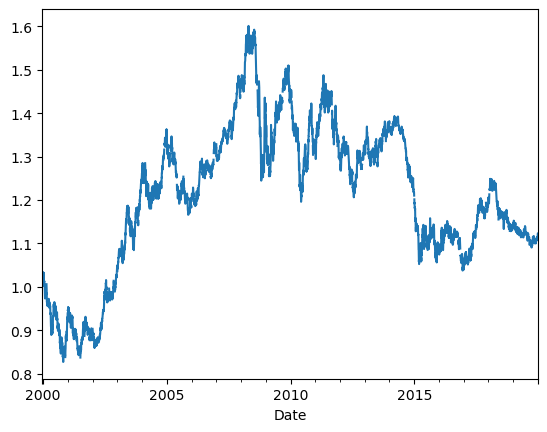

In [7]:
EURUSD_close.plot()

In [8]:
EURUSD_close.shift()

Date
1999-12-15       NaN
1999-12-16    1.0066
1999-12-17    1.0169
1999-12-20    1.0088
1999-12-21    1.0066
               ...  
2019-12-25    1.1084
2019-12-26       NaN
2019-12-27    1.1102
2019-12-30    1.1174
2019-12-31    1.1217
Name: EURUSD, Length: 5230, dtype: float64

In [9]:
EURUSD_returns = 100 * np.log(EURUSD_close/EURUSD_close.shift())

In [10]:
plt.figure()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Axes: xlabel='Date'>

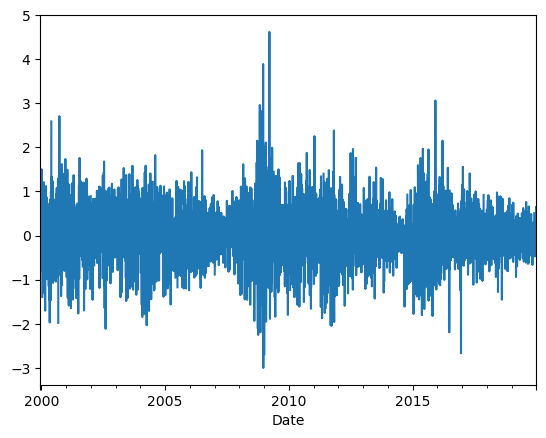

In [11]:
EURUSD_returns.plot()

In [12]:
EURUSD_returns

Date
1999-12-15         NaN
1999-12-16    1.018047
1999-12-17   -0.799728
1999-12-20   -0.218319
1999-12-21    0.267871
                ...   
2019-12-25         NaN
2019-12-26         NaN
2019-12-27    0.646438
2019-12-30    0.384083
2019-12-31    0.089111
Name: EURUSD, Length: 5230, dtype: float64

In [13]:
EURUSD_returns_90_19 = EURUSD_returns["19900101":]

TypeError: index type not supported

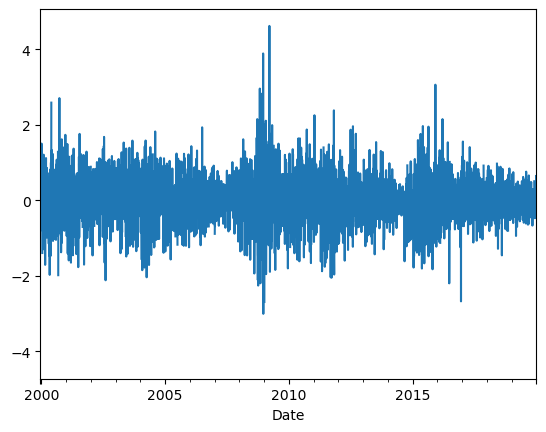

In [14]:
EURUSD_returns_90_19.plot()

# white noise
from SFUtilities import ARMASimulator

y = ARMASimulator()
wn = pd.Series(y)
wn.plot()


In [ ]:
#checking for white noise
print("mean of the time series:", wn.mean() )
print("variation of the time series:", wn.var())
print("autocorrelation:", wn.autocorr())

In [ ]:
# %load SFUtilities.py
"""Utilities for the Udemy course Statisics for Finance"""

"""
Copyright (c) 2022 Cameron R. Connell

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt

def autocorr(series, max_lag=100, vlim=None, title=None, ax=None, tests=None):
    """
        Calculates and displays the autocorrelation function of a
        Pandas series

        Parameters
        ----------
        series: series
            A Pandas series whose autocorrelation function will be calculated
            and displayed
        max_lag: int
            The maximum lag of autocorrelations to calculate and display
            (defaults to 100)
        vlim: list
            A Python list with 2 elements containing the vertical axis limits
            for the plot (defaults to [-1.1, 1.1])
        title: string
            A title for the plot (defaults to "Autocorrelation Function)
        ax: axes
            A matplotlib axes object in which the plot will be placed
            if provided
        tests: int
            If set, the plot will display the 95% confidence limits, and the
            Ljung-Box statistic will be calculated and reported

        Returns
        -------
        series
            A Pandas series containing the autocorrelations of the data series
    """

    length = len(series)

    if max_lag >= length - 1:
        print("Warning: maximum lag exceeds series length")
        print("Maximum lag reduced to series length")
        print("Correlation for lags approaching series length unreliable")
        max_lag = length - 2

    lags = [i for i in range(max_lag)]
    acorr = [series.autocorr(h) for h in lags]
    acorr_array = np.array(acorr)
    denoms = [length - i for i in range(1, max_lag)]
    denoms_array = np.array(denoms)
    factors = 1.0 / denoms_array

    if ax is None:
        fig = plt.figure()
        ax = fig.subplots()
    
    for h in lags:
        ax.vlines(h, 0.0, acorr[h], color='b')
    
    ax.hlines(0, 0, max_lag, linestyles='dashed', color='black')

    if tests is not None:
        level = 1.96 / sqrt(length)
        ax.hlines(level, 0, max_lag, linestyles='dashdot', color='magenta')
        ax.hlines(-level, 0, max_lag, linestyles='dashdot', color='magenta')

        acorr_squared = acorr_array * acorr_array
        lb = length * (length + 2) * np.dot(acorr_squared[1:], factors)
        if max_lag > 0.1 * length:
            print("Warning: For Ljung-Box test, max_lag < 10% series length recommended")
        print("Ljung-Box test statistic =", lb)

    if vlim is None:
        vlim = [-1.1, 1.1]
    
    ax.set_ylim(vlim)

    if title == None:
        title = "Autocorrelation Function"

    ax.set_xlabel('lag', fontsize=15)
    ax.set_ylabel('correlation', fontsize=15)
    ax.set_title(title, fontsize=25)

    return pd.Series(acorr)


def ARMASimulator(ar_params=None, ma_params=None, const=0, scale=1, offset=1000, size=1000):
    """
        Simulates ARMA(p,q) processes

        Parameters
        ----------
        ar_params: list
            The autoregressive coefficients for the ARMA(p,q) process
            that will be simulated
        ma_params: list
            The moving average coefficients for the ARMA(p,q) process
            that will be simulated
        const: float
            The constant in the ARMA(p,q) process. Defaults to 0.
        scale: float
            The scale/standard deviation of the underlying normal white
            noise process
        offset: int
            The number of simulated steps to be generated before the
            returned time series.  Defaults to 1000
        size: int
            The length of the simulated series.  Defaults to 1000

        Returns
        -------
        Numpy array
            A Numpy array containing the simulated time series
    """

    if ar_params is not None:
        p = len(ar_params)
        phi = np.array(ar_params)
    else:
        p=0
        phi = np.array([])

    if ma_params is not None:
        q = len(ma_params)
        theta = np.array(ma_params)
    else:
        q=0
        theta = np.array([])
    
    r=max(p,q)

    size += offset
    wn = scale * np.random.randn(size)

    init = np.random.randn(r+1)

    x = np.zeros(size)
    x[:r+1] = init

    for i in range(r+1, size):
        x[i] = const + np.dot(phi, x[i-1: i-p-1: -1]) + wn[i] + np.dot(theta, wn[i-1: i-q-1: -1])
    
    return x[offset:]


def turning_points(series):

    n = len(series)

    count = 0    
    for i in range(1, len(series)-1):
        if (series[i] - series[i-1]) * (series[i] - series[i+1]) > 0:
            count += 1
    
    mean = 2 * (n - 2) / 3
    variance = (16 * n - 29) / 90

    z = (count - mean) / sqrt(variance)

    print("# of turning points =", count)

    print("z-score = ", z)
    
    return count


def runs_up_down(series):

    n = len(series)

    count = 0
    for i in range(1,n):
        if series[i] >= series[i-1]:
            count += 1

    n1 = count
    n2 = n - n1 - 1

    count = 1
    for i in range(1, n-1):
        if (series[i+1] - series[i]) * (series[i] - series[i-1]) < 0:
            count += 1
    
    mean = 1 + 2 * n1 * n2 / (n1 + n2)
    variance = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / (n1 + n2)**2 / (n1 + n2 + 1)

    z = (count - mean) / sqrt(variance)

    print("number of runs = ", count)
    print("z-score = ", z)

    return count

In [ ]:
y = ARMASimulator(const=2, scale=3)

In [ ]:
wn_2_9 = pd.Series(y)
wn_2_9

In [ ]:
print("mean of the time series:", wn_2_9.mean() )
print("variation of the time series:", wn_2_9.var())
print("autocorrelation:", wn_2_9.autocorr())

In [ ]:
from scipy import stats

#H0: mean = 2
t_stat, p_value = stats.ttest_1samp(wn_2_9, 2)

print(p_value)

if p_value > 0.05:
    print("H0 hipotezi reddedilemez. Ortalama 2'dir")

else:
    print("İstatistiksel olarak ortalama 2'den farklıdır")

In [18]:
n_steps = 100
drift = 5
volatility = 2

white_noise = np.random.normal(loc=0, scale=volatility, size=n_steps)
increments = drift + white_noise
random_walk = np.cumsum(increments)
random_walk = np.insert(0, 0, random_walk)


In [23]:
plt.figure()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

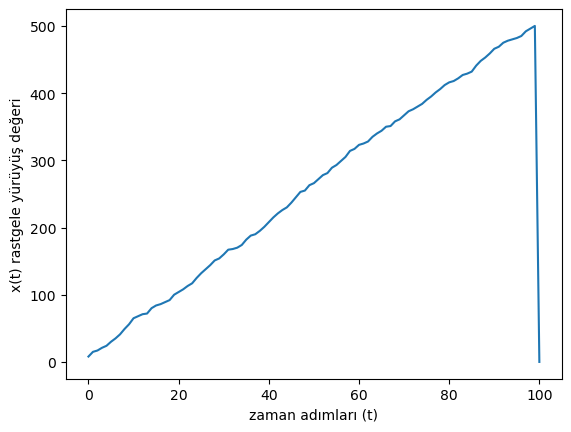

In [25]:
plt.xlabel("zaman adımları (t)")
plt.ylabel("x(t) rastgele yürüyüş değeri")
plt.plot(random_walk)
